In [1]:
!pip install -q transformers==5.8.0 peft accelerate pillow datasets torchao>=0.16.0 torchvision

In [2]:
!pip install -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 82.5 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [3]:
import os
import torch
from datasets import load_dataset
from PIL import Image
from peft import LoraConfig, get_peft_model
from torch.utils.data import Dataset
from transformers import (
    AutoProcessor,
    Gemma4ForConditionalGeneration,
    Trainer,
    TrainingArguments,
)

# ── Configuration ──────────────────────────────────────────────
MODEL_ID = "google/gemma-4-E4B-it"
HF_DATASET = "lmoroney/uiscreenshots"
OUTPUT_DIR = "./results/ui-vision-v1"
ADAPTER_DIR = "./adapters/ui-vision-v1"
MAX_LENGTH = 1024
NUM_EPOCHS = 10
LEARNING_RATE = 2e-5
LORA_RANK = 8
LORA_ALPHA = 8
LORA_DROPOUT = 0.1
BATCH_SIZE = 2
GRAD_ACCUM = 16

# ── Part 1: Model Loading ─────────────────────────────────────
print("Loading model and processor...")

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Gemma4ForConditionalGeneration.from_pretrained(
    MODEL_ID,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

print(f"\nModel class: {type(model).__name__}")
print(f"Vision tower:   {model.model.vision_tower.__class__.__name__}")
print(f"Projector:      {model.model.embed_vision.__class__.__name__}")
print(f"Language model:  {model.model.language_model.__class__.__name__}")

# ── Part 2: LoRA Configuration ────────────────────────────────
print("\nConfiguring LoRA...")

from transformers.models.gemma4.modeling_gemma4 import Gemma4ClippableLinear
from peft.tuners.lora.model import LoraModel

if not getattr(LoraModel, "_clippable_patched", False):
    _orig_create_module = LoraModel._create_new_module

    @staticmethod
    def _create_module_with_clippable(config, adapter_name, target, **kw):
        if isinstance(target, Gemma4ClippableLinear):
            target = target.linear
        return _orig_create_module(config, adapter_name, target, **kw)

    LoraModel._create_new_module = _create_module_with_clippable
    LoraModel._clippable_patched = True

projector_linears = [
    name for name, mod in model.model.embed_vision.named_modules()
    if isinstance(mod, torch.nn.Linear)
]
print(f"Projector linear layers: {projector_linears}")

lora_config = LoraConfig(
    r=LORA_RANK,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        # Language model layers (same as Chapter 7)
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
        # Strategy 2: adapt the projector's layers too
        *projector_linears,
    ],
    # Keep the vision and audio towers frozen -- their attention
    # layers share names (q_proj etc.) with the language model's
    exclude_modules=r".*(vision_tower|audio).*",
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

# Verify the adapters landed where we intended: expect entries under
# the language model AND embed_vision, and NONE under vision_tower
lora_locations = sorted({
    n.split(".lora")[0] for n, _ in model.named_modules() if ".lora" in n
})
assert any("embed_vision" in n for n in lora_locations), \
    "Projector did not get LoRA adapters!"
assert not any("vision_tower" in n for n in lora_locations), \
    "Vision tower got LoRA adapters -- it should be frozen!"
print(f"LoRA attached to {len(lora_locations)} modules; "
      f"projector included, vision tower untouched ✓")

# ── Part 3: Dataset ───────────────────────────────────────────
class VisionChatDataset(Dataset):
    def __init__(self, hf_split, processor, max_length: int = 1024):
        self.hf_split = hf_split
        self.processor = processor
        self.max_length = max_length

    def __len__(self):
        return len(self.hf_split)

    def __getitem__(self, idx):
        example = self.hf_split[idx]
        messages = example["messages"]

        images = []
        if "image" in example and example["image"] is not None:
            images.append(example["image"].convert("RGB"))

        clean_messages = []
        for msg in messages:
            if isinstance(msg["content"], list):
                clean_parts = []
                for part in msg["content"]:
                    if part.get("type") == "image":
                        clean_parts.append({"type": "image"})
                    else:
                        clean_parts.append(part)
                clean_messages.append({"role": msg["role"],
                                       "content": clean_parts})
            else:
                clean_messages.append(msg)

        text = self.processor.apply_chat_template(
            clean_messages, tokenize=False, add_generation_prompt=False
        )

        inputs = self.processor(
            text=text,
            images=images if images else None,
            return_tensors="pt",
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
        )

        inputs = {k: v.squeeze(0) for k, v in inputs.items()}
        inputs["labels"] = inputs["input_ids"].clone()
        inputs["labels"][inputs["attention_mask"] == 0] = -100

        return inputs


print(f"\nDownloading dataset from {HF_DATASET}...")
hf_dataset = load_dataset(HF_DATASET)

train_dataset = VisionChatDataset(hf_dataset["train"], processor,
                                  max_length=MAX_LENGTH)
val_dataset = VisionChatDataset(hf_dataset["validation"], processor,
                                max_length=MAX_LENGTH)

print(f"Train: {len(train_dataset)} examples")
print(f"Val:   {len(val_dataset)} examples")

# ── Part 4: Training ──────────────────────────────────────────
print("\nConfiguring training...")

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=NUM_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    weight_decay=0.05,
    max_grad_norm=0.3,
    bf16=True,
    logging_steps=5,
    logging_first_step=True,
    report_to="tensorboard",
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="steps",
    save_steps=40,
    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    gradient_checkpointing=False,
    optim="adamw_torch",
    remove_unused_columns=False,
)


def collate_fn(examples):
    batch = {}
    for key in examples[0].keys():
        batch[key] = torch.stack([ex[key] for ex in examples])
    return batch


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=collate_fn,
)

print("\nStarting training...")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  Batch size: {BATCH_SIZE} x {GRAD_ACCUM} = {BATCH_SIZE * GRAD_ACCUM}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  LoRA rank: {LORA_RANK}")
print()

trainer.train()

# Save the adapter
os.makedirs(ADAPTER_DIR, exist_ok=True)
trainer.save_model(ADAPTER_DIR)
processor.save_pretrained(ADAPTER_DIR)

print(f"\nTraining complete!")
print(f"Adapter saved to {ADAPTER_DIR}")

Loading model and processor...


processor_config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/18.6k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.14k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.08k [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/250 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/28 [00:00<?, ? examples/s]

Train: 250 examples
Val:   28 examples

Configuring training...

Starting training...
  Epochs: 10
  Batch size: 2 x 16 = 32
  Learning rate: 2e-05
  LoRA rank: 8



Step,Training Loss,Validation Loss
20,8.767129,8.196388
40,5.505076,5.241578
60,4.632074,4.522881
80,4.422386,4.406178



Training complete!
Adapter saved to ./adapters/ui-vision-v1


In [4]:
import shutil
from google.colab import files

shutil.make_archive("ui-vision-v1", "zip", "./adapters/ui-vision-v1")
files.download("ui-vision-v1.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Inference

In [5]:
import zipfile, os

os.makedirs("./adapters/ui-vision-v1", exist_ok=True)
with zipfile.ZipFile("ui-vision-v1.zip", "r") as z:
    z.extractall("./adapters/ui-vision-v1")

In [6]:
# Based on chapter11/code/vision_inference.py (simplified for inline use)
import torch
from PIL import Image
from transformers import AutoProcessor, Gemma4ForConditionalGeneration
from transformers.models.gemma4.modeling_gemma4 import Gemma4ClippableLinear
from peft.tuners.lora.model import LoraModel
from peft import PeftModel

# ── Configuration ──────────────────────────────────────────────

MODEL_ID = "google/gemma-4-E4B-it"
ADAPTER_PATH = "./adapters/ui-vision-v1"

# Load base model (same bf16 setup as training)
processor = AutoProcessor.from_pretrained(ADAPTER_PATH)
base_model = Gemma4ForConditionalGeneration.from_pretrained(
    MODEL_ID,
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

if not getattr(LoraModel, "_clippable_patched", False):
    _orig_create_module = LoraModel._create_new_module

    @staticmethod
    def _create_module_with_clippable(config, adapter_name, target, **kw):
        if isinstance(target, Gemma4ClippableLinear):
            target = target.linear
        return _orig_create_module(config, adapter_name, target, **kw)

    LoraModel._create_new_module = _create_module_with_clippable
    LoraModel._clippable_patched = True


# Load the fine-tuned adapter
model = PeftModel.from_pretrained(base_model, ADAPTER_PATH)
model.eval()


def ask_about_image(image, question: str) -> str:
    """Send an image and question to the fine-tuned VLM.

    Args:
        image: A PIL Image, or a file path string.
        question: The question to ask about the image.
    """
    if isinstance(image, str):
        image = Image.open(image).convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question},
            ],
        }
    ]

    # Apply chat template
    text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    # Process text + image
    inputs = processor(
        text=text,
        images=[image],
        return_tensors="pt",
    ).to(model.device)

    # Generate
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=1024,
            temperature=0.3,
            do_sample=True,
        )

    # Decode only the generated tokens
    generated = output_ids[0][inputs["input_ids"].shape[1]:]
    return processor.decode(generated, skip_special_tokens=True)

Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

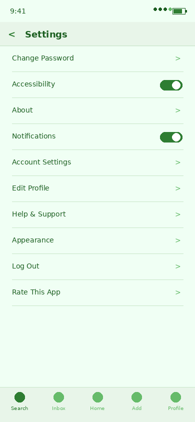

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:2356: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncation strategy. To pad to max length, use `padding='max_length'`.
  warnings.warn(


```json
{
  "audit_summary": {
    "wcag_compliance_score": "Good",
    "usability_score": "Good",
    "overall_assessment": "The UI is clean, follows standard mobile design patterns, and appears largely compliant with WCAG guidelines. Key areas for minor improvement relate to color contrast in specific states and ensuring all interactive elements meet touch target size requirements."
  },
  "wcag_analysis": [
    {
      "id": "1.4.3_Contrast_Minimum",
      "severity": "Minor",
      "description": "While the primary text and background contrast seems adequate, ensure that the color used for the active/selected state indicators (if any are present outside the visible area) meets the 4.5:1 ratio against adjacent colors.",
      "recommendation": "Verify the contrast ratio for all text and interactive elements, especially subtle state changes."
    },
    {
      "id": "1.4.11_Non_text_Contrast",
      "severity": "Minor",
      "description": "The toggle switch background and the swit

In [7]:
from datasets import load_dataset
from IPython.display import display

dataset = load_dataset("lmoroney/uiscreenshots")
test_image = dataset["validation"][0]["image"]

display(test_image.resize((195, 422)))  # Half size so it fits the notebook

response = ask_about_image(
    test_image,
    "Audit this mobile UI screenshot for WCAG compliance and "
    "usability issues. Return structured JSON."
)
print(response)

Select a test image to upload:


Saving ui_checkout_504.png to ui_checkout_504.png


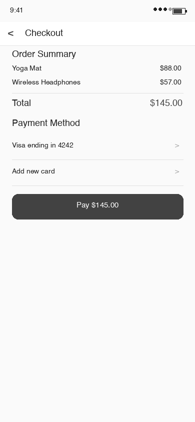


--- ui_checkout_504.png ---
```json
{
  "audit_summary": {
    "wcag_compliance": "Partial Compliance",
    "usability_score": "Good",
    "overall_recommendation": "The design is clean and functional, but several accessibility improvements are needed, particularly around contrast and focus indication."
  },
  "wcag_issues": [
    {
      "id": "1.4.3",
      "level": "AA",
      "description": "Contrast (Minimum)",
      "severity": "Medium",
      "details": "While the text generally appears readable, the contrast between the light gray background elements (like the dividers or inactive states) and the surrounding white/black text should be verified to meet WCAG AA standards (4.5:1 for normal text).",
      "recommendation": "Ensure all text and interactive elements meet a minimum contrast ratio of 4.5:1 against their background."
    },
    {
      "id": "2.4.7",
      "level": "AA",
      "description": "Focus Visible",
      "severity": "High",
      "details": "There is no visib

In [8]:
# Upload a test image and run inference
from google.colab import files
from PIL import Image
from IPython.display import display

# Upload an image file
print("Select a test image to upload:")
uploaded = files.upload()

# Run inference on the uploaded image
for filename in uploaded:
    img = Image.open(filename).convert("RGB")
    display(img.resize((195, 422)))

    response = ask_about_image(
        img,
        "Audit this mobile UI screenshot for WCAG compliance and "
        "usability issues. Return structured JSON"
    )
    print(f"\n--- {filename} ---")
    print(response)

In [9]:
print(f"Response length: {len(processor.tokenizer.tokenize(response))} tokens")
print(f"Response chars: {len(response)}")

Response length: 817 tokens
Response chars: 3229


In [10]:
import time
start = time.time()
response = ask_about_image(test_image, "What color is the background?")
print(f"{time.time() - start:.1f}s")
print(response)

1.3s
The background color is **white**.


# Evaluation


In [ ]:
"""
Chapter 11: Vision Model Evaluation Script
============================================
Evaluates a fine-tuned VLM using:
1. Mismatch test — checks whether the model attends to image content
2. LLM-as-a-judge — uses a teacher VLM to grade responses

Usage:
    export API_KEY="sk-..."
    python chapter11_vision_eval.py

Requires:
    - A fine-tuned adapter at ./adapters/ui-vision-v1
    - Test images in ./images/test/
    - An OpenAI-compatible API for the judge model
"""

import base64
import json
import os
import sys
from difflib import SequenceMatcher
from pathlib import Path

import torch
from openai import OpenAI
from PIL import Image
from peft import PeftModel
from transformers import (
    AutoProcessor,
    Gemma4ForConditionalGeneration,
)
from transformers.models.gemma4.modeling_gemma4 import Gemma4ClippableLinear
from peft.tuners.lora.model import LoraModel

# ── Configuration ──────────────────────────────────────────────
MODEL_ID = "google/gemma-4-E4B-it"
ADAPTER_PATH = os.getenv("ADAPTER_PATH", "./adapters/ui-vision-v1")
TEST_DIR = os.getenv("TEST_DIR", "./images/test")
EVAL_OUTPUT = os.getenv("EVAL_OUTPUT", "./eval_vision_results.json")

# Judge model config — In this case I hosted a Gemma-4-31B on a cloud service.
ENDPOINT_URL = os.getenv("ENDPOINT_URL",
    "<ENDPOINT URL>")
API_KEY = os.getenv("API_KEY",
    "<DEFAULT API KEY>")
JUDGE_MODEL = os.getenv("JUDGE_MODEL", "google/gemma-4-31B-it")

client = OpenAI(base_url=ENDPOINT_URL, api_key=API_KEY)


# ── Model Loading ─────────────────────────────────────────────
def load_model():
    if not getattr(LoraModel, "_clippable_patched", False):
      _orig_create_module = LoraModel._create_new_module

      @staticmethod
      def _create_module_with_clippable(config, adapter_name, target, **kw):
          if isinstance(target, Gemma4ClippableLinear):
              target = target.linear
          return _orig_create_module(config, adapter_name, target, **kw)

      LoraModel._create_new_module = _create_module_with_clippable
      LoraModel._clippable_patched = True
    """Load the fine-tuned VLM."""
    print("Loading model...")
    processor = AutoProcessor.from_pretrained(ADAPTER_PATH)
    base_model = Gemma4ForConditionalGeneration.from_pretrained(
        MODEL_ID,
        device_map="auto",
        torch_dtype=torch.bfloat16,
    )
    model = PeftModel.from_pretrained(base_model, ADAPTER_PATH)
    model.eval()
    print("Model loaded.\n")
    return model, processor


def ask_about_image(model, processor, image_path: str, question: str) -> str:
    """Send an image and question to the VLM."""
    image = Image.open(image_path).convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question},
            ],
        }
    ]

    text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = processor(text=text, images=[image], return_tensors="pt").to(model.device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs, max_new_tokens=512, temperature=0.3, do_sample=True
        )

    generated = output_ids[0][inputs["input_ids"].shape[1] :]
    return processor.decode(generated, skip_special_tokens=True)


# ── Evaluation 1: Mismatch Test ──────────────────────────────
def mismatch_test(
    model, processor, image_a: str, image_b: str, question: str
) -> dict:
    """Test whether the model's answer changes when the image changes.

    If the model produces very similar responses for two different images,
    it may not be attending to the visual content.
    """
    response_a = ask_about_image(model, processor, image_a, question)
    response_b = ask_about_image(model, processor, image_b, question)

    similarity = SequenceMatcher(None, response_a, response_b).ratio()

    return {
        "image_a": image_a,
        "image_b": image_b,
        "question": question,
        "response_a": response_a[:200] + "..." if len(response_a) > 200 else response_a,
        "response_b": response_b[:200] + "..." if len(response_b) > 200 else response_b,
        "similarity": round(similarity, 3),
        "likely_using_image": similarity < 0.7,
    }


def run_mismatch_tests(model, processor, test_images: list[str]) -> list[dict]:
    """Run mismatch tests on pairs of test images."""
    question = "Describe the UI layout and elements in this screenshot."
    results = []

    for i in range(0, len(test_images) - 1, 2):
        img_a = test_images[i]
        img_b = test_images[i + 1]
        print(
            f"  Mismatch test: {Path(img_a).name} vs {Path(img_b).name}...",
            end=" ",
        )

        result = mismatch_test(model, processor, img_a, img_b, question)
        status = "PASS" if result["likely_using_image"] else "FAIL"
        print(f"similarity={result['similarity']:.3f} [{status}]")
        results.append(result)

    return results


# ── Evaluation 2: LLM-as-a-Judge ─────────────────────────────
def encode_image(image_path: str) -> str:
    """Read an image file and return its base64 encoding."""
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")


JUDGE_SYSTEM = """You are evaluating a VLM's description of a UI screenshot.
You can see the original screenshot. Grade the response on:

1. ACCURACY (1-5): Does the description match what's actually in the image?
2. COMPLETENESS (1-5): Are all major UI elements mentioned?
3. SPECIFICITY (1-5): Does it describe THIS screenshot, not a generic screen?
4. USEFULNESS (1-5): Would a developer find this analysis actionable?

Reply with ONLY a JSON object:
{"accuracy": N, "completeness": N, "specificity": N,
 "usefulness": N, "total": N, "reasoning": "one sentence"}

where total = accuracy + completeness + specificity + usefulness (max 20)."""


def judge_vision_response(image_path: str, question: str, response: str) -> dict:
    """Have a teacher VLM grade the fine-tuned model's response."""
    b64 = encode_image(image_path)
    ext = Path(image_path).suffix.lower().lstrip(".")
    mime = {"png": "image/png", "jpg": "image/jpeg", "jpeg": "image/jpeg"}.get(
        ext, "image/png"
    )

    try:
        judge_response = client.chat.completions.create(
            model=JUDGE_MODEL,
            messages=[
                {"role": "system", "content": JUDGE_SYSTEM},
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "image_url",
                            "image_url": {"url": f"data:{mime};base64,{b64}"},
                        },
                        {
                            "type": "text",
                            "text": (
                                f"Question asked: {question}\n\n"
                                f"Model's response:\n{response}\n\n"
                                f"Grade this response."
                            ),
                        },
                    ],
                },
            ],
            temperature=0.1,
            max_tokens=300,
        )
        content = judge_response.choices[0].message.content.strip()
        # Try to parse JSON from the response
        if "```" in content:
            content = content.split("```")[1]
            if content.startswith("json"):
                content = content[4:]
        return json.loads(content)
    except Exception as e:
        print(f"  Judge error: {e}")
        return {
            "accuracy": 0,
            "completeness": 0,
            "specificity": 0,
            "usefulness": 0,
            "total": 0,
            "reasoning": f"Judge error: {e}",
        }


def run_judge_evaluation(
    model, processor, test_images: list[str]
) -> list[dict]:
    """Run LLM-as-a-judge evaluation on test images."""
    question = "Analyze this mobile app screenshot."
    results = []

    for img_path in test_images:
        print(f"  Judging response for {Path(img_path).name}...", end=" ")

        response = ask_about_image(model, processor, img_path, question)
        scores = judge_vision_response(img_path, question, response)

        print(f"total={scores.get('total', 'N/A')}/20")
        results.append(
            {
                "image": img_path,
                "response": response[:300] + "..."
                if len(response) > 300
                else response,
                "scores": scores,
            }
        )

    return results


# ── Main ──────────────────────────────────────────────────────
def main():
    # Find test images
    test_dir = Path(TEST_DIR)
    if not test_dir.exists():
        print(f"Error: Test directory '{TEST_DIR}' does not exist.")
        print("Create the directory and add test screenshots.")
        sys.exit(1)

    test_images = sorted(
        str(p)
        for p in test_dir.iterdir()
        if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
    )

    if len(test_images) < 2:
        print(f"Need at least 2 test images in {TEST_DIR}")
        sys.exit(1)

    print(f"Found {len(test_images)} test images in {TEST_DIR}\n")

    # Load model
    model, processor = load_model()

    # Run evaluations
    all_results = {}

    print("=" * 50)
    print("1. MISMATCH TESTS (image grounding)")
    print("=" * 50)
    mismatch_results = run_mismatch_tests(model, processor, test_images)
    all_results["mismatch_tests"] = mismatch_results

    passing = sum(1 for r in mismatch_results if r["likely_using_image"])
    total = len(mismatch_results)
    print(f"\nMismatch test summary: {passing}/{total} passed\n")

    print("=" * 50)
    print("2. LLM-AS-A-JUDGE (response quality)")
    print("=" * 50)
    judge_results = run_judge_evaluation(model, processor, test_images[:5])
    all_results["judge_results"] = judge_results

    if judge_results:
        avg_total = sum(
            r["scores"].get("total", 0) for r in judge_results
        ) / len(judge_results)
        print(f"\nAverage judge score: {avg_total:.1f}/20\n")

    # Save results
    with open(EVAL_OUTPUT, "w") as f:
        json.dump(all_results, f, indent=2)
    print(f"Full results saved to {EVAL_OUTPUT}")


if __name__ == "__main__":
    main()


Found 3 test images in ./images/test

Loading model...


Loading weights:   0%|          | 0/2076 [00:00<?, ?it/s]

Model loaded.

1. MISMATCH TESTS (image grounding)
  Mismatch test: ui_chat_527.png vs ui_checkout_517.png... 

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:2356: UserWarning: `max_length` is ignored when `padding`=`True` and there is no truncation strategy. To pad to max length, use `padding='max_length'`.
  warnings.warn(


similarity=0.084 [PASS]

Mismatch test summary: 1/1 passed

2. LLM-AS-A-JUDGE (response quality)
  Judging response for ui_chat_527.png...   Judge error: Request timed out.
total=0/20
  Judging response for ui_checkout_517.png...   Judge error: Request timed out.
total=0/20
  Judging response for ui_home_feed_522.png...   Judge error: Request timed out.
total=0/20

Average judge score: 0.0/20

Full results saved to ./eval_vision_results.json
